Disability: found 419 rows with blank text (not NaN) and a 67.8% no-show rate. Decision: convert blanks to NaN and merge with the 16,601 missing into “Unknown” (17,020 rows, ~46% no-show).

In [19]:
text_cols = df.select_dtypes(include=["object", "string"]).columns
for c in text_cols:
    blanks = (df[c].astype(str).str.strip() == "").sum()
    print(c, "->", blanks, "blank values")

specialty -> 0 blank values
gender -> 0 blank values
no_show -> 0 blank values
disability -> 0 blank values
place -> 0 blank values
appointment_shift -> 0 blank values
rain_intensity -> 0 blank values
heat_intensity -> 0 blank values
appointment_date_continuous -> 0 blank values
place_filled -> 0 blank values


In [18]:
# Step 1: turn empty or whitespace-only text into real missing values
df["disability"] = df["disability"].replace(r"^\s*$", pd.NA, regex=True)

# Step 2: fill all missing with "Unknown"
df["disability"] = df["disability"].fillna("Unknown")

# Check
df["disability"].value_counts(dropna=False)

disability
intellectual    62852
motor           29721
Unknown         17020
Name: count, dtype: int64

Place: Named cities have 6 to 12% no-show rates; missing place (10.5% of rows) has ~35%. Very strong signal. Decision: fill with “Unknown”.
Rain intensity: ~31 to 33% across all levels, so almost no effect.
Disability: intellectual (29.0%) and motor (29.1%) are similar; missing disability is 46.3%. An extra blank-label group (67.8% no-show) needs investigating.

In [17]:
df["disability"].value_counts(dropna=False)

disability
intellectual    62852
motor           29721
NaN             16601
                  419
Name: count, dtype: int64

In [16]:
df["disability"].fillna("Unknown").pipe(lambda s: df.groupby(s)["no_show_flag"].mean() * 100).round(1).sort_values()

disability
intellectual    29.0
motor           29.1
Unknown         46.3
                67.8
Name: no_show_flag, dtype: float64

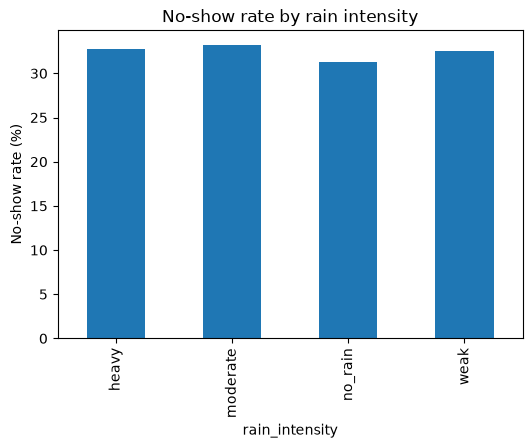

In [15]:
rate = df.groupby("rain_intensity")["no_show_flag"].mean() * 100
rate.plot(kind="bar", figsize=(6, 4))
plt.ylabel("No-show rate (%)")
plt.title("No-show rate by rain intensity")
plt.show()

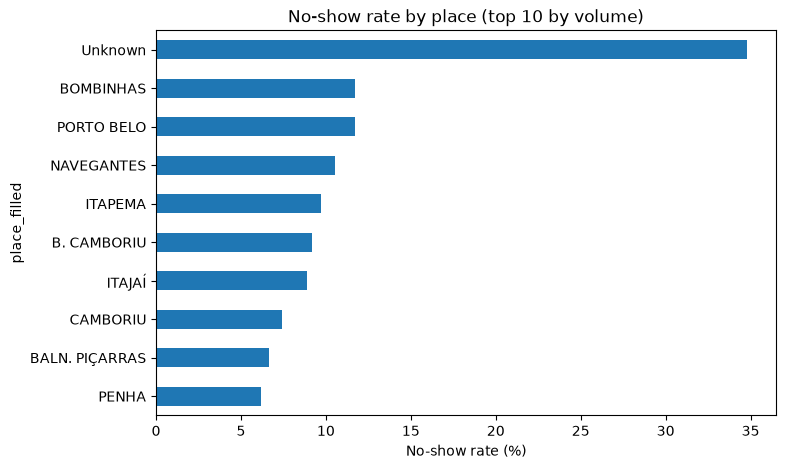

In [14]:
df["place_filled"] = df["place"].fillna("Unknown")
top = df["place_filled"].value_counts().head(10).index
rate = df[df["place_filled"].isin(top)].groupby("place_filled")["no_show_flag"].mean() * 100
rate.sort_values().plot(kind="barh", figsize=(8, 5))
plt.xlabel("No-show rate (%)")
plt.title("No-show rate by place (top 10 by volume)")
plt.show()

Age: No-show rate peaks at 18 to 40 (~45%), falls to ~22% for over 60. Strong pattern. Missing age (21% of rows) has 33.2% vs 31.4%, only slightly different. Decision: fill with median, add an age_missing flag.
Shift: Morning (~33%) slightly higher than afternoon (~31%). Weak effect.

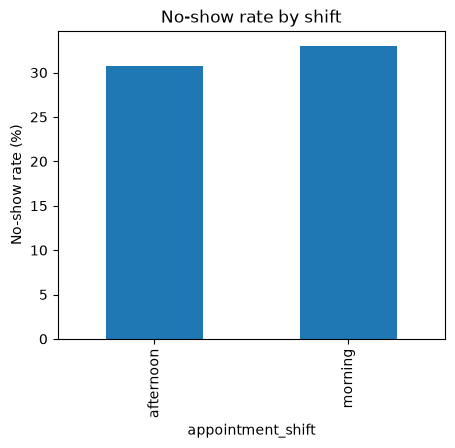

In [13]:
rate = df.groupby("appointment_shift")["no_show_flag"].mean() * 100
rate.plot(kind="bar", figsize=(5, 4))
plt.ylabel("No-show rate (%)")
plt.title("No-show rate by shift")
plt.show()

In [12]:
df["age_missing"] = df["age"].isnull()
df.groupby("age_missing")["no_show_flag"].mean() * 100

age_missing
False    31.397966
True     33.236063
Name: no_show_flag, dtype: float64

findings so far:
SMS received: no difference (~31.7% vs ~31.9%)
Specialty: physiotherapy and psychotherapy highest among large groups; “sem especialidade” is tiny

In [10]:
df["specialty"].fillna("Unknown").pipe(lambda s: df.groupby(s)["no_show_flag"].mean() * 100).round(1).sort_values()

specialty
pedagogo                16.0
enf                     19.8
occupational therapy    23.9
assist                  26.9
speech therapy          27.9
psychotherapy           32.3
physiotherapy           34.4
Unknown                 40.6
sem especialidade       52.8
Name: no_show_flag, dtype: float64

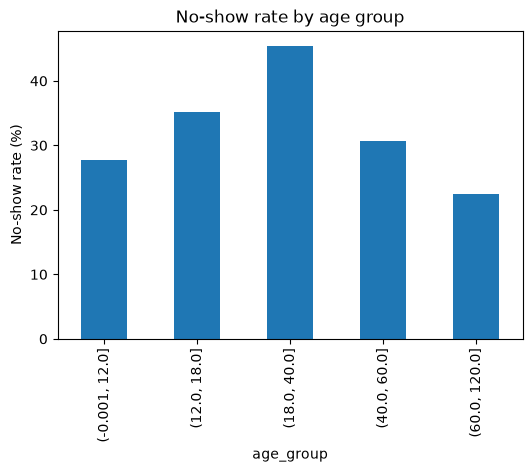

In [11]:
df["age_group"] = pd.cut(df["age"], bins=[0, 12, 18, 40, 60, 120], include_lowest=True)
rate = df.groupby("age_group", observed=True)["no_show_flag"].mean() * 100
rate.plot(kind="bar", figsize=(6, 4))
plt.ylabel("No-show rate (%)")
plt.title("No-show rate by age group")
plt.show()

In [9]:
df["specialty"].value_counts(dropna=False)

specialty
psychotherapy           28645
speech therapy          22322
physiotherapy           21004
NaN                     20127
occupational therapy    11319
pedagogo                 3536
enf                      1681
assist                    635
sem especialidade         324
Name: count, dtype: int64

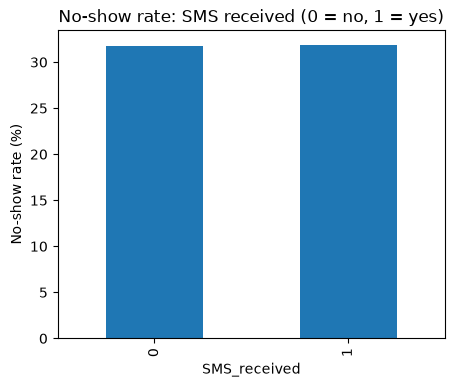

In [8]:
rate = df.groupby("SMS_received")["no_show_flag"].mean() * 100
rate.plot(kind="bar", figsize=(5, 4))
plt.ylabel("No-show rate (%)")
plt.title("No-show rate: SMS received (0 = no, 1 = yes)")
plt.show()

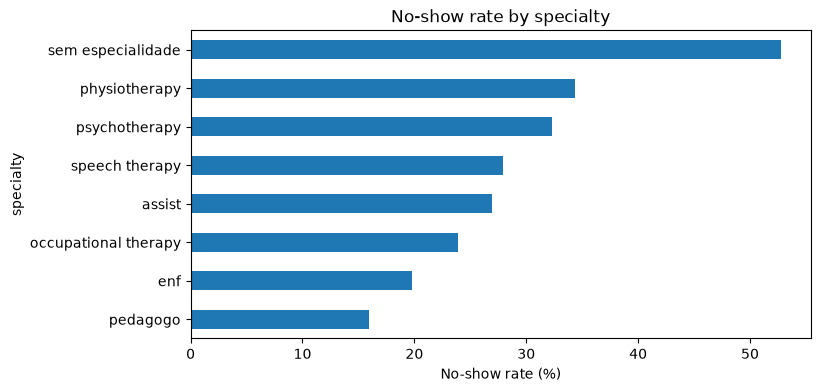

In [7]:
rate = df.groupby("specialty")["no_show_flag"].mean() * 100
rate.sort_values().plot(kind="barh", figsize=(8, 4))
plt.xlabel("No-show rate (%)")
plt.title("No-show rate by specialty")
plt.show()

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

df["no_show_flag"] = (df["no_show"] == "yes").astype(int)

In [5]:
df["no_show"].value_counts(normalize=True) * 100

no_show
no     68.216948
yes    31.783052
Name: proportion, dtype: float64

In [4]:
df["no_show"].value_counts()

no_show
no     74761
yes    34832
Name: count, dtype: int64

In [3]:
(df.isnull().mean() * 100).round(1).sort_values(ascending=False)

age                            21.0
specialty                      18.4
disability                     15.1
place                          10.5
max_rain_day                    2.1
average_temp_day                2.0
average_rain_day                2.0
max_temp_day                    2.0
appointment_time                0.0
no_show                         0.0
over_60_years_old               0.0
under_12_years_old              0.0
appointment_shift               0.0
gender                          0.0
patient_needs_companion         0.0
rainy_day_before                0.0
storm_day_before                0.0
rain_intensity                  0.0
heat_intensity                  0.0
appointment_date_continuous     0.0
Hipertension                    0.0
Diabetes                        0.0
Alcoholism                      0.0
Handcap                         0.0
Scholarship                     0.0
SMS_received                    0.0
dtype: float64

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 109593 entries, 0 to 109592
Data columns (total 26 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   specialty                    89466 non-null   str    
 1   appointment_time             109593 non-null  int64  
 2   gender                       109593 non-null  str    
 3   no_show                      109593 non-null  str    
 4   disability                   92992 non-null   str    
 5   place                        98054 non-null   str    
 6   appointment_shift            109593 non-null  str    
 7   age                          86633 non-null   float64
 8   under_12_years_old           109593 non-null  int64  
 9   over_60_years_old            109593 non-null  int64  
 10  patient_needs_companion      109593 non-null  int64  
 11  average_temp_day             107382 non-null  float64
 12  average_rain_day             107348 non-null  float64
 13  max_temp_d

In [1]:
import pandas as pd

df = pd.read_csv("C:/noshow_project/data/Medical_appointment_data.csv")
print(df.shape)
df.head()

(109593, 26)


,specialty,appointment_time,gender,no_show,disability,place,appointment_shift,age,under_12_years_old,over_60_years_old,...,storm_day_before,rain_intensity,heat_intensity,appointment_date_continuous,Hipertension,Diabetes,Alcoholism,Handcap,Scholarship,SMS_received
0,psychotherapy,17,F,yes,intellectual,Lake Marvinville,afternoon,9.0,1,0,...,1,no_rain,warm,2020-01-01,0,0,0,0,0,0
1,NaN,7,M,no,intellectual,ITAPEMA,morning,11.0,1,0,...,1,no_rain,cold,2020-01-01,0,0,0,0,0,0
2,speech therapy,16,M,no,intellectual,ITAJAÍ,afternoon,8.0,1,0,...,1,no_rain,warm,2020-01-01,0,0,0,0,0,0
3,speech therapy,14,M,yes,intellectual,Sarahside,afternoon,9.0,1,0,...,1,moderate,mild,2020-01-01,0,0,0,0,0,1
4,physiotherapy,8,M,no,motor,ITAJAÍ,morning,NaN,0,0,...,1,no_rain,mild,2020-01-01,0,0,0,0,0,0


In [2]:
import pandas as pd
print("It works!", pd.__version__)

Exception ignored in PyObject_HasAttr(); consider using PyObject_HasAttrWithError(), PyObject_GetOptionalAttr() or PyObject_GetAttr():
Traceback (most recent call last):
  File "<frozen importlib._bootstrap>", line 491, in _call_with_frames_removed
ImportError: PyCapsule_Import could not import module "pandas"


It works! 3.1.1
